<a href="https://colab.research.google.com/github/erloyz/progetto-ml-pun/blob/master/notebooks/01_data_ingestion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Progetto Machine Learning: Previsione del Prezzo Unico Nazionale (PUN)

**Corso:** Machine Learning e Data Mining (Modulo 2)  
**Dataset:** Prezzi orari MGP (GME) & Dati Meteo Zonali (Open-Meteo) 2024–2025  

---

### Business Understanding & Obiettivi del Progetto
Questo notebook costituisce la prima fase del progetto end-to-end sviluppato secondo la metodologia **CRISP-DM**:

1. **Obiettivo:** Costruire una pipeline di data Ingestion, aggregazione esogena e Feature Engineering per prevedere il prezzo orario dell'energia elettrica in Italia (PUN).
2. **Setup dell'Ambiente:** Sincronizzazione automatica del repository GitHub (`erloyz/progetto-ml-pun`) e verifica dell'integrità dei dati grezzi (`data/raw/`).
3. **Fasi coperte in questo notebook:**
   - **Data Ingestion & Cleaning:** Ingestion dei 730 file XML orari del GME e parsing del dataset meteo Open-Meteo.
   - **Data Integration:** Aggregazione spaziale delle stazioni meteo (Nord vs Centro-Sud) e join temporale sui timestamp.
   - **Feature Engineering:** Trasformazioni cicliche ($\sin/\cos$), flag calendariali e feature autoregressive (Lag & Rolling mean).
   - **Data Split:** Suddivisione cronologica rigorosa (Train/Test) per prevenire il data leakage nelle serie storiche.

In [80]:
# --- LIBRERIE STANDARD E DI SISTEMA ---
import os
import warnings
warnings.filterwarnings('ignore')

# --- MANIPOLAZIONE DATI E CALCOLO NUMERICO ---
import pandas as pd
import numpy as np

# --- VISUALIZZAZIONE DATI ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- MACHINE LEARNING (Scikit-Learn) ---
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
# (Aggiungeremo qui gli estimatori e i modelli nelle fasi successive)

In [81]:
# Riconoscimento dell'ambiente di esecuzione
if os.path.exists("/content"):
    # Ambiente Google Colab
    if not os.path.exists("progetto-ml-pun"):
        !git clone https://github.com/erloyz/progetto-ml-pun.git
    %cd /content/progetto-ml-pun
else:
    # Ambiente Locale (Mac / VS Code)
    # Se il notebook è eseguito dentro 'notebooks/', risale alla radice del progetto
    if os.path.basename(os.getcwd()) == "notebooks":
        %cd ..

# Verifica del percorso corrente e dei dati
print("📍 Working Directory corrente:", os.getcwd())
assert os.path.exists("data/raw"), "❌ Errore: Cartella 'data/raw' non trovata nella root del progetto!"
print("✅ Dati grezzi trovati:", os.listdir("data/raw"))

📍 Working Directory corrente: /Users/erloyz/Desktop/uni/dm-ml/ml/progetto-ml-pun
✅ Dati grezzi trovati: ['.DS_Store', 'open-meteo.csv', 'pun_monthly']


## 1\. Data Ingestion - Prezzi d'Asta del PUN (GME)

In questa fase importiamo e concateniamo le rilevazioni orarie del Prezzo Unico Nazionale (PUN) relative al biennio 2024-2025 presenti nella cartella \`data/raw/pun\_monthly\`.

I file XML ufficiali del GME vengono letti programmaticamente con \`pd.read\_xml()\` e uniti in un unico DataFrame Pandas tramite \`pd.concat()\`.

In [82]:
path_pun = "data/raw/pun_monthly"
lista_pun = []

print("Lettura dei file XML del PUN in corso...")

for radice, sottocartelle, file_presenti in os.walk(path_pun):
    for file in sorted(file_presenti):
        if not file.startswith('.') and file.lower().endswith('.xml'):
            percorso_file = os.path.join(radice, file)
            try:
                df_giornaliero = pd.read_xml(percorso_file)
                lista_pun.append(df_giornaliero)
            except Exception as e:
                print(f"Attenzione, errore nella lettura di {file}: {e}")

if lista_pun:
    # Unione di tutti i file
    df_pun = pd.concat(lista_pun, ignore_index=True)

    # Selezione colonne principali
    colonne_da_tenere = [c for c in ['Data', 'Ora', 'PUN'] if c in df_pun.columns]
    if colonne_da_tenere:
        df_pun = df_pun[colonne_da_tenere]

        # -------------------------------------------------------------------
        # CONVERSIONE DEFINITIVA ED INCONDIZIONATA A FLOAT
        # Sostituiamo la virgola col punto e convertiamo in float64 a prescindere dal dtype iniziale
        # -------------------------------------------------------------------
        df_pun['PUN'] = pd.to_numeric(
            df_pun['PUN'].astype(str).str.replace(',', '.'), 
            errors='coerce'
        )

        # Gestiamo eventuali valori nulli o non convertibili in 'Ora' prima della conversione ad intero
        df_pun = df_pun.dropna(subset=['Ora'])
        df_pun['Ora'] = df_pun['Ora'].astype(int)

        # Pulizia della data da eventuali decimali (.0) e conversione a datetime
        df_pun['Data'] = df_pun['Data'].astype(str).str.split('.').str[0]
        df_pun['Data'] = pd.to_datetime(df_pun['Data'], format='%Y%m%d', errors='coerce')

        # Rimuoviamo eventuali righe con dati mancanti (sia sulla data che sul PUN)
        df_pun = df_pun.dropna(subset=['Data', 'PUN'])

        # Creazione della colonna 'timestamp' oraria unificata (es. 2024-01-01 00:00:00)
        # L'ora 1 del GME corrisponde alle 00:00 (Ora - 1)
        df_pun['timestamp'] = df_pun['Data'] + pd.to_timedelta(df_pun['Ora'] - 1, unit='h')

        # Ordiniamo cronologicamente la serie storica
        df_pun = df_pun.sort_values(by='timestamp').reset_index(drop=True)

        # Re-ordiniamo le colonne in modo pulito
        df_pun = df_pun[['timestamp', 'Data', 'Ora', 'PUN']]

        print("\n✅ Ingestion, pulizia e conversione float completate!")
        print(f"Dimensioni finali DataFrame: {df_pun.shape[0]} righe e {df_pun.shape[1]} colonne.")
        print(f"Tipo di dato colonna PUN: {df_pun['PUN'].dtype}")

        # Visualizzazione prime 10 righe
        display(df_pun.head(10))
else:
    print("Nessun file XML trovato nella cartella specificata.")

Lettura dei file XML del PUN in corso...

✅ Ingestion, pulizia e conversione float completate!
Dimensioni finali DataFrame: 17544 righe e 4 colonne.
Tipo di dato colonna PUN: float64


,timestamp,Data,Ora,PUN
0,2024-01-01 00:00:00,2024-01-01,1,107.09
1,2024-01-01 01:00:00,2024-01-01,2,104.00
2,2024-01-01 02:00:00,2024-01-01,3,100.00
3,2024-01-01 03:00:00,2024-01-01,4,85.66
4,2024-01-01 04:00:00,2024-01-01,5,85.00
5,2024-01-01 05:00:00,2024-01-01,6,85.53
6,2024-01-01 06:00:00,2024-01-01,7,95.07
7,2024-01-01 07:00:00,2024-01-01,8,104.07
8,2024-01-01 08:00:00,2024-01-01,9,106.95
9,2024-01-01 09:00:00,2024-01-01,10,107.08


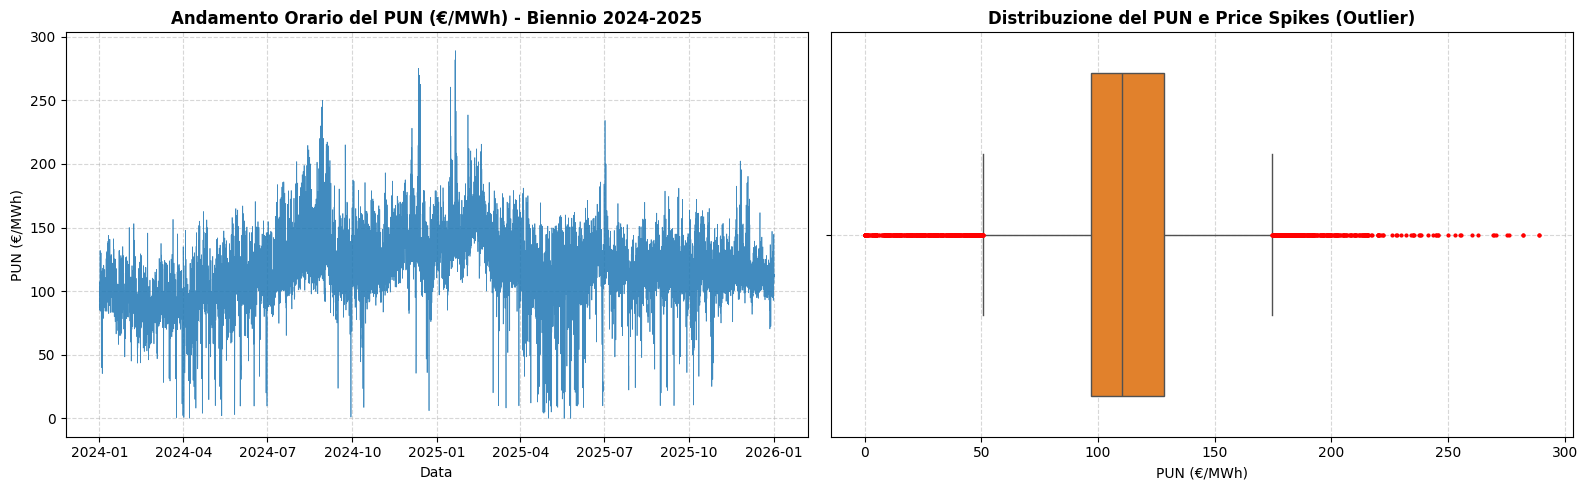

In [83]:
# --- EXPLORATORY DATA ANALYSIS (EDA) DEL PUN ---

# Conversione del PUN in numerico (float) gestendo eventuali virgole nei decimali
df_pun['PUN'] = pd.to_numeric(
    df_pun['PUN'].astype(str).str.replace(',', '.'), 
    errors='coerce'
)

# Conversione della colonna temporale in datetime
df_pun['timestamp'] = pd.to_datetime(df_pun['timestamp'])

# Pulizia da valori non validi e ordinamento cronologico rigoroso
df_pun = df_pun.dropna(subset=['PUN', 'timestamp']).sort_values('timestamp').reset_index(drop=True)

# Inizializzazione della figura con 2 subplot affiancati
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- SUBPLOT 1: Serie Temporale Oraria del PUN ---
axes[0].plot(df_pun['timestamp'], df_pun['PUN'], color='#1f77b4', linewidth=0.5, alpha=0.85)
axes[0].set_title("Andamento Orario del PUN (€/MWh) - Biennio 2024-2025", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Data")
axes[0].set_ylabel("PUN (€/MWh)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- SUBPLOT 2: Boxplot per la Distribuzione e Rilevamento Outlier (Price Spikes) ---
sns.boxplot(
    x=df_plot['PUN'], 
    ax=axes[1], 
    color='#ff7f0e', 
    flierprops={'marker': 'o', 'markersize': 2, 'markerfacecolor': 'red', 'markeredgecolor': 'red'}
)
axes[1].set_title("Distribuzione del PUN e Price Spikes (Outlier)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("PUN (€/MWh)")
axes[1].grid(True, linestyle='--', alpha=0.5)

# 4. Ottimizzazione del layout e visualizzazione
plt.tight_layout()
plt.show()

## 1.2 Data Ingestion & Aggregazione Spaziale - Dati Meteo (Open-Meteo)

In questa sezione importiamo e prepariamo le **variabili meteorologiche esogene** ricavate dal servizio Open-Meteo per il biennio 2024–2025.

#### Parsing del File CSV
Il dataset grezzo (`data/raw/open-meteo.csv`) presenta una struttura mista: contiene un'anagrafica iniziale delle stazioni seguita dalle misurazioni orarie vere e proprie per ciascuna città.
Per gestire correttamente l'ingestion:
* Individuiamo l'indice dell'intestazione oraria per separare i metadati dalle serie storiche.
* Estraiamo le serie orarie relative alle 6 stazioni di riferimento: **Milano, Torino, Venezia** (per la zona Nord) e **Bari, Napoli, Roma** (per la zona Centro-Sud).
* Convertiamo i valori numerici (`temperature_2m`, `wind_speed_10m`, `shortwave_radiation`) in `float` e la colonna temporale in formato `datetime` (`timestamp`).

#### Aggregazione Spaziale Zonale
Per prevenire problemi di **multicollinearità** tra stazioni vicine e ridurre la dimensionalità delle feature, applichiamo un'aggregazione spaziale mediante la media aritmetica oraria all'interno delle due macro-aree:
$$\text{Metrica}_{\text{Zona}} = \frac{1}{N} \sum_{i=1}^{N} \text{Metrica}_{i}$$
Otteniamo così una struttura tabellare piatta affiancata, pronti per l'unione (`pd.merge`) con la serie storica del PUN sulla chiave temporale comune `timestamp`.


In [84]:
# --- INGESTION E PULIZIA AVANZATA DATI METEO LOCALI ---
path_meteo = "data/raw/open-meteo.csv"

# Lettura diretta del file di dati grezzi
df_raw = pd.read_csv(path_meteo)

# Individuazione dell'indice di riga in cui inizia l'intestazione dei dati orari
header_hourly_idx = df_raw[df_raw.iloc[:, 0] == 'location_id'].index[0]

# Estrazione dei dati orari a partire dalla riga successiva alla seconda intestazione
df_meteo = df_raw.iloc[header_hourly_idx + 1:].copy()

# Impostazione dei nomi di colonna corretti presi dalla riga della seconda intestazione
df_meteo.columns = df_raw.iloc[header_hourly_idx].values

# Selezione delle colonne utili e rimozione di eventuali colonne/artefatti con valori NaN
colonne_utili = ['location_id', 'time', 'temperature_2m (°C)', 'wind_speed_10m (km/h)', 'shortwave_radiation (W/m²)']
df_meteo = df_meteo[colonne_utili].dropna(subset=['time']).reset_index(drop=True)

# Conversione esplicita dei tipi di dato
df_meteo['location_id'] = df_meteo['location_id'].astype(int)
df_meteo['timestamp'] = pd.to_datetime(df_meteo['time'])

# Conversione a float delle colonne contenenti le metriche meteo
metric_cols = ['temperature_2m (°C)', 'wind_speed_10m (km/h)', 'shortwave_radiation (W/m²)']
for col in metric_cols:
    df_meteo[col] = df_meteo[col].astype(float)

# Selezione e ordinamento finale delle colonne meteo pulite
df_meteo = df_meteo[['timestamp', 'location_id'] + metric_cols]

print("✅ Ingestion e parsing meteo completati!")
print(f"Dimensioni totali dataset meteo orario: {df_meteo.shape[0]} righe e {df_meteo.shape[1]} colonne.")
print(f"Location ID presenti: {sorted(df_meteo['location_id'].unique())}")
display(df_meteo.head(10))

✅ Ingestion e parsing meteo completati!
Dimensioni totali dataset meteo orario: 105264 righe e 5 colonne.
Location ID presenti: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


,timestamp,location_id,temperature_2m (°C),wind_speed_10m (km/h),shortwave_radiation (W/m²)
0,2024-01-01 00:00:00,0,6.2,7.8,0.0
1,2024-01-01 01:00:00,0,5.6,11.0,0.0
2,2024-01-01 02:00:00,0,6.1,8.6,0.0
3,2024-01-01 03:00:00,0,5.0,10.1,0.0
4,2024-01-01 04:00:00,0,4.2,9.9,0.0
5,2024-01-01 05:00:00,0,3.6,10.8,0.0
6,2024-01-01 06:00:00,0,3.2,11.3,0.0
7,2024-01-01 07:00:00,0,3.3,13.3,0.0
8,2024-01-01 08:00:00,0,3.3,11.7,0.0
9,2024-01-01 09:00:00,0,3.3,9.5,22.0


In [85]:
# --- AGGREGAZIONE SPAZIALE METEO PER MACRO-AREE (NORD vs CENTRO-SUD) ---

# Mappatura dei location_id nelle macro-aree geografiche
mappa_zone = {
    0: 'Nord',       # Milano
    1: 'Nord',       # Torino
    2: 'Nord',       # Venezia
    3: 'CentroSud',  # Bari
    4: 'CentroSud',  # Napoli
    5: 'CentroSud'   # Roma
}

df_meteo['zona'] = df_meteo['location_id'].map(mappa_zone)

# Aggregazione oraria per zona tramite media aritmetica
df_meteo_zonale = df_meteo.groupby(['timestamp', 'zona'])[[
    'temperature_2m (°C)',
    'wind_speed_10m (km/h)',
    'shortwave_radiation (W/m²)'
]].mean().reset_index()

# Pivot della tabella per avere Nord e Centro-Sud su colonne affiancate
df_meteo_pivot = df_meteo_zonale.pivot(
    index='timestamp',
    columns='zona'
)

# Appiattimento MultiIndex usando variabili semplici (metrica, zona) per evitare l'errore di unpacking
df_meteo_pivot.columns = [
    f"{metrica.split(' ')[0]}_{zona}"
    for metrica, zona in df_meteo_pivot.columns
]

# Riportiamo il timestamp a colonna standard
df_meteo_pivot = df_meteo_pivot.reset_index()

print("✅ Aggregazione zonale completata!")
print(f"Dimensioni dataset meteo aggregato: {df_meteo_pivot.shape[0]} righe e {df_meteo_pivot.shape[1]} colonne.")
display(df_meteo_pivot.head(20))

✅ Aggregazione zonale completata!
Dimensioni dataset meteo aggregato: 17544 righe e 7 colonne.


,timestamp,temperature_2m_CentroSud,temperature_2m_Nord,wind_speed_10m_CentroSud,wind_speed_10m_Nord,shortwave_radiation_CentroSud,shortwave_radiation_Nord
0,2024-01-01 00:00:00,12.500000,4.933333,17.000000,8.600000,0.000000,0.000000
1,2024-01-01 01:00:00,12.466667,4.433333,16.100000,7.800000,0.000000,0.000000
2,2024-01-01 02:00:00,12.900000,5.066667,17.466667,6.800000,0.000000,0.000000
3,2024-01-01 03:00:00,12.733333,4.366667,16.500000,8.666667,0.000000,0.000000
4,2024-01-01 04:00:00,12.600000,4.033333,16.100000,8.166667,0.000000,0.000000
5,2024-01-01 05:00:00,12.366667,3.233333,15.000000,8.233333,0.000000,0.000000
6,2024-01-01 06:00:00,12.233333,2.800000,14.133333,7.033333,0.000000,0.000000
7,2024-01-01 07:00:00,12.033333,2.500000,12.333333,7.466667,0.000000,0.000000
8,2024-01-01 08:00:00,12.400000,2.366667,14.300000,7.266667,8.000000,0.000000
9,2024-01-01 09:00:00,13.833333,2.666667,12.700000,6.533333,85.666667,31.000000


## 1.3 Data Integration - Merge Finale PUN & Meteo Aggregato

In questa fase unifichiamo le due sorgenti dati eterogenee elaborate nei passi precedenti:
1. La serie storica oraria dei prezzi d'asta **PUN** (proveniente dal GME).
2. Il dataset delle **variabili meteorologiche esogene** zonali (temperatura, velocità del vento e radiazione solare aggregate per Nord e Centro-Sud).

#### Strategia di Integration (Inner Join basato su Timestamp)
Appliciamo un'operazione di **Primary Key-based Data Integration** coordinata sulla chiave temporale continua `timestamp`:

$$\text{DataFrame}_{\text{Finale}} = \text{PUN} \bowtie_{\text{timestamp}} \text{Meteo}_{\text{Zonale}}$$

* **Garantire la Coerenza Temporale:** Il join interno (`how='inner'`) assicura che ciascuna osservazione oraria del PUN sia perfettamente allineata al corrispondente profilo meteo dello stesso istante temporale.
* **Integrità dei Dati:** Rimuoviamo eventuali record incompleti o discrepanze di copertura agli estremi del periodo osservato (2024–2025).
* **Controllo Valori Mancanti:** Verifichiamo che la matrice unificata risultante sia priva di valori nulli (`NaN`), pronta per la fase di Feature Engineering temporale ed autoregressiva.

In [86]:
# --- MERGE FINALE PUN + METEO AGGREGATO ---

# Join interno basato sulla chiave temporale 'timestamp'
df_final = pd.merge(df_pun, df_meteo_pivot, on='timestamp', how='inner')

print("✅ Join completato con successo!")
print(f"Dimensioni dataset finale integrato: {df_final.shape[0]} righe e {df_final.shape[1]} colonne.")
print(f"Valori nulli totali nel dataset finale: {df_final.isnull().sum().sum()}")

# Visualizzazione prime 10 righe della matrice unificata
display(df_final.head(10))

✅ Join completato con successo!
Dimensioni dataset finale integrato: 17544 righe e 10 colonne.
Valori nulli totali nel dataset finale: 0


,timestamp,Data,Ora,PUN,temperature_2m_CentroSud,temperature_2m_Nord,wind_speed_10m_CentroSud,wind_speed_10m_Nord,shortwave_radiation_CentroSud,shortwave_radiation_Nord
0,2024-01-01 00:00:00,2024-01-01,1,107.09,12.500000,4.933333,17.000000,8.600000,0.000000,0.0
1,2024-01-01 01:00:00,2024-01-01,2,104.00,12.466667,4.433333,16.100000,7.800000,0.000000,0.0
2,2024-01-01 02:00:00,2024-01-01,3,100.00,12.900000,5.066667,17.466667,6.800000,0.000000,0.0
3,2024-01-01 03:00:00,2024-01-01,4,85.66,12.733333,4.366667,16.500000,8.666667,0.000000,0.0
4,2024-01-01 04:00:00,2024-01-01,5,85.00,12.600000,4.033333,16.100000,8.166667,0.000000,0.0
5,2024-01-01 05:00:00,2024-01-01,6,85.53,12.366667,3.233333,15.000000,8.233333,0.000000,0.0
6,2024-01-01 06:00:00,2024-01-01,7,95.07,12.233333,2.800000,14.133333,7.033333,0.000000,0.0
7,2024-01-01 07:00:00,2024-01-01,8,104.07,12.033333,2.500000,12.333333,7.466667,0.000000,0.0
8,2024-01-01 08:00:00,2024-01-01,9,106.95,12.400000,2.366667,14.300000,7.266667,8.000000,0.0
9,2024-01-01 09:00:00,2024-01-01,10,107.08,13.833333,2.666667,12.700000,6.533333,85.666667,31.0


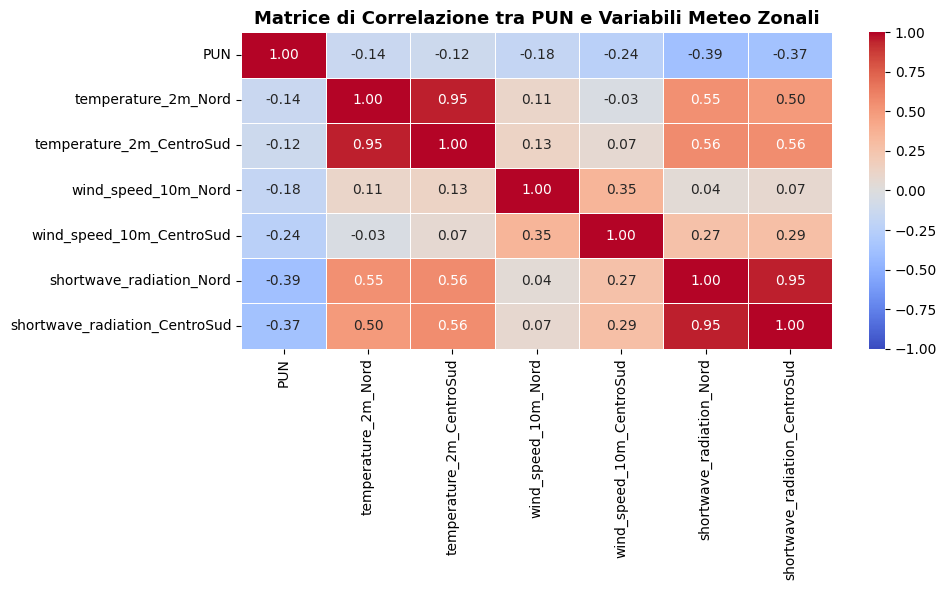

In [87]:
# --- HEATMAP DI CORRELAZIONE PUN E METEO ZONALE ---
plt.figure(figsize=(10, 6))

# Selezione delle colonne numeriche per la correlazione
colonne_corr = [
    'PUN', 
    'temperature_2m_Nord', 'temperature_2m_CentroSud', 
    'wind_speed_10m_Nord', 'wind_speed_10m_CentroSud', 
    'shortwave_radiation_Nord', 'shortwave_radiation_CentroSud'
]

# Calcolo della matrice di correlazione di Pearson
corr_matrix = df_final[colonne_corr].corr()

# Generazione della heatmap
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)

plt.title("Matrice di Correlazione tra PUN e Variabili Meteo Zonali", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. Feature Engineering Temporale & Serie Storiche

Per consentire ai modelli di Machine Learning (come algoritmi basati su alberi o regressioni regolarizzate) di apprendere i pattern temporali e le dinamiche del mercato elettrico (MGP), costruiamo tre famiglie di feature aggiuntive.

#### 2.1. Trasformazioni Trigonometriche Cicliche ($\sin / \cos$)
L'ora del giorno ($0..23$) e il mese ($1..12$) sono variabili cicliche: l'ora 23:00 dista solo 1 ora dalle 00:00. Per evitare che i modelli interpretino queste variabili come ordinate lineari (dove 23 e 0 sono numericamente lontani), proiettiamo il tempo su una circonferenza unitaria:
$$x_{\text{ciclo}} = \sin\left(\frac{2\pi \cdot t}{T}\right), \quad y_{\text{ciclo}} = \cos\left(\frac{2\pi \cdot t}{T}\right)$$
dove $T=24$ per le ore e $T=12$ per i mesi.

#### 2.2. Feature Calendariali
Inseriamo una variabile binaria (`is_weekend`) per indicare il fine settimana (Sabato e Domenica), momento in cui la domanda industriale di energia elettrica subisce una forte flessione.

#### 2.3. Lag Features e Rolling Windows (Autoregressione)
Aggiungiamo la "memoria storica" del PUN per supportare orizzonti di previsione a 24h, 48h e 72h:
* **Lag Features:** Valori del PUN a $t-24$, $t-48$, $t-72$ e $t-168$ (stessa ora del giorno della settimana precedente).
* **Rolling Mean (Media Mobile 24h):** Media aritmetica mobile applicata sul PUN shiftato a $t-24$ per catturare il trend di medio periodo.

> ⚠️ **Prevenzione del Data Leakage:** Applicare uno `shift(24)` prima del calcolo delle rolling feature garantisce che nessuna informazione futura legata all'orizzonte di test venga accidentalmente utilizzata durante la predizione.

Dopo aver generato le feature autoregressive, le prime 168 righe del dataset (corrispondenti alla prima settimana di gennaio 2024) presenteranno valori nulli (`NaN`) dovuti allo shift massimo ($t-168$). Tali righe vengono rimosse con `.dropna()`, restituendo una matrice solida e priva di dati mancanti a partire dall'8 gennaio 2024.

In [88]:
# --- FEATURE ENGINEERING TEMPORALE E LAG FEATURES ---

# Lavoro su una copia pulita del DataFrame finale
df_fe = df_final.copy()

# ASSICURATI CHE IL PUN SIA NUMERICO (Float)
df_fe['PUN'] = pd.to_numeric(df_fe['PUN'].astype(str).str.replace(',', '.'), errors='coerce')

# ESTRAZIONE DI VARIABILI CICLICHE TEMPORALI (SIN/COS)
df_fe['ora_num'] = df_fe['timestamp'].dt.hour
df_fe['mese_num'] = df_fe['timestamp'].dt.month
df_fe['giorno_settimana'] = df_fe['timestamp'].dt.dayofweek

df_fe['sin_ora'] = np.sin(2 * np.pi * df_fe['ora_num'] / 24)
df_fe['cos_ora'] = np.cos(2 * np.pi * df_fe['ora_num'] / 24)
df_fe['sin_mese'] = np.sin(2 * np.pi * df_fe['mese_num'] / 12)
df_fe['cos_mese'] = np.cos(2 * np.pi * df_fe['mese_num'] / 12)

df_fe['is_weekend'] = df_fe['giorno_settimana'].isin([5, 6]).astype(int)

# CREAZIONE DELLE LAG FEATURES DEL PUN (Ritardi storici)
lags = [24, 48, 72, 168]
for lag in lags:
    df_fe[f'pun_lag_{lag}'] = df_fe['PUN'].shift(lag)

# Media mobile a 24h spostata di 24h (evita data leakage)
df_fe['pun_rolling_mean_24h'] = df_fe['PUN'].shift(24).rolling(window=24).mean()

# GESTIONE VALORI NULLI DERIVATI DAI LAG
df_fe = df_fe.dropna().reset_index(drop=True)

print("✅ Feature Engineering completato con successo!")
print(f"Nuove dimensioni DataFrame: {df_fe.shape[0]} righe e {df_fe.shape[1]} colonne.")
display(df_fe.head(10))

✅ Feature Engineering completato con successo!
Nuove dimensioni DataFrame: 17376 righe e 23 colonne.


,timestamp,Data,Ora,PUN,temperature_2m_CentroSud,temperature_2m_Nord,wind_speed_10m_CentroSud,wind_speed_10m_Nord,shortwave_radiation_CentroSud,shortwave_radiation_Nord,...,sin_ora,cos_ora,sin_mese,cos_mese,is_weekend,pun_lag_24,pun_lag_48,pun_lag_72,pun_lag_168,pun_rolling_mean_24h
0,2024-01-08 00:00:00,2024-01-08,1,87.60,9.166667,6.066667,8.866667,6.866667,0.000000,0.000000,...,0.000000,1.000000e+00,0.5,0.866025,0,96.85,97.50,86.07515,107.09,100.708333
1,2024-01-08 01:00:00,2024-01-08,2,85.28,8.833333,6.033333,8.066667,7.300000,0.000000,0.000000,...,0.258819,9.659258e-01,0.5,0.866025,0,96.58,97.67,88.96000,104.00,100.662917
2,2024-01-08 02:00:00,2024-01-08,3,85.28,9.433333,6.866667,9.566667,8.166667,0.000000,0.000000,...,0.500000,8.660254e-01,0.5,0.866025,0,93.80,93.00,78.50000,100.00,100.696250
3,2024-01-08 03:00:00,2024-01-08,4,90.79,9.133333,6.766667,9.466667,8.800000,0.000000,0.000000,...,0.707107,7.071068e-01,0.5,0.866025,0,93.80,93.00,78.50000,85.66,100.729583
4,2024-01-08 04:00:00,2024-01-08,5,93.80,8.800000,6.600000,9.200000,9.133333,0.000000,0.000000,...,0.866025,5.000000e-01,0.5,0.866025,0,85.93,89.70,79.39000,85.00,100.572500
5,2024-01-08 05:00:00,2024-01-08,6,90.79,8.700000,6.533333,10.666667,8.466667,0.000000,0.000000,...,0.965926,2.588190e-01,0.5,0.866025,0,84.30,89.47,79.60000,85.53,100.357083
6,2024-01-08 06:00:00,2024-01-08,7,107.46,8.566667,6.366667,9.100000,7.866667,0.000000,0.000000,...,1.000000,6.123234e-17,0.5,0.866025,0,85.00,91.96,103.46000,95.07,100.067083
7,2024-01-08 07:00:00,2024-01-08,8,114.18,8.333333,6.000000,9.400000,6.633333,0.000000,0.000000,...,0.965926,-2.588190e-01,0.5,0.866025,0,102.27,96.75,111.19000,104.07,100.297083
8,2024-01-08 08:00:00,2024-01-08,9,125.50,8.300000,5.533333,10.466667,6.966667,4.000000,0.000000,...,0.866025,-5.000000e-01,0.5,0.866025,0,100.55,94.66,115.00000,106.95,100.542500
9,2024-01-08 09:00:00,2024-01-08,10,123.00,9.133333,5.666667,11.666667,8.633333,58.333333,11.333333,...,0.707107,-7.071068e-01,0.5,0.866025,0,101.19,100.50,120.40000,107.08,100.571250


## 3. Split Cronologico del Dataset (Train/Test Split)

Nelle serie temporali non si può utilizzare uno split casuale (`train_test_split` con shuffling), poiché violerebbe l'ordine temporale generando **data leakage** (il modello imparerebbe dal "futuro" per predire il "passato").

Applichiamo uno **split cronologico rigoroso**:
- **Training Set:** dall'8 Gennaio 2024 (data di inizio effettiva dopo la rimozione dei primi 168 `NaN` causati dalle lag feature) al 30 Giugno 2025 (~75% dei dati puliti).
- **Test Set:** dal 1° Luglio 2025 al 31 Dicembre 2025 (~25% dei dati).

In [89]:
# --- SPLIT CRONOLOGICO TRAIN / TEST ---

# Definizione della data di cutoff per separare Train e Test set
data_cutoff = "2025-07-01 00:00:00"

# Isolamento della matrice delle feature (X) e del target PUN (y)
target_col = "PUN"
feature_cols = [col for col in df_fe.columns if col not in [target_col, "timestamp"]]

# Maschera booleana per lo split temporale
train_mask = df_fe["timestamp"] < data_cutoff
test_mask = df_fe["timestamp"] >= data_cutoff

# Creazione delle matrici Train e Test
X_train = df_fe.loc[train_mask, feature_cols]
y_train = df_fe.loc[train_mask, target_col]

X_test = df_fe.loc[test_mask, feature_cols]
y_test = df_fe.loc[test_mask, target_col]

# Verifica dinamica delle date effettive
start_train = df_fe.loc[train_mask, 'timestamp'].min()
end_train = df_fe.loc[train_mask, 'timestamp'].max()
start_test = df_fe.loc[test_mask, 'timestamp'].min()
end_test = df_fe.loc[test_mask, 'timestamp'].max()

print("=== RISULTATO SPLIT CRONOLOGICO ===")
print(f"Periodo di Training: {start_train} --> {end_train}")
print(f"Periodo di Testing:  {start_test} --> {end_test}")
print(f"\nDimensioni X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"Dimensioni X_test:  {X_test.shape}  | y_test:  {y_test.shape}")

=== RISULTATO SPLIT CRONOLOGICO ===
Periodo di Training: 2024-01-08 00:00:00 --> 2025-06-30 23:00:00
Periodo di Testing:  2025-07-01 00:00:00 --> 2025-12-31 23:00:00

Dimensioni X_train: (12959, 21) | y_train: (12959,)
Dimensioni X_test:  (4417, 21)  | y_test:  (4417,)


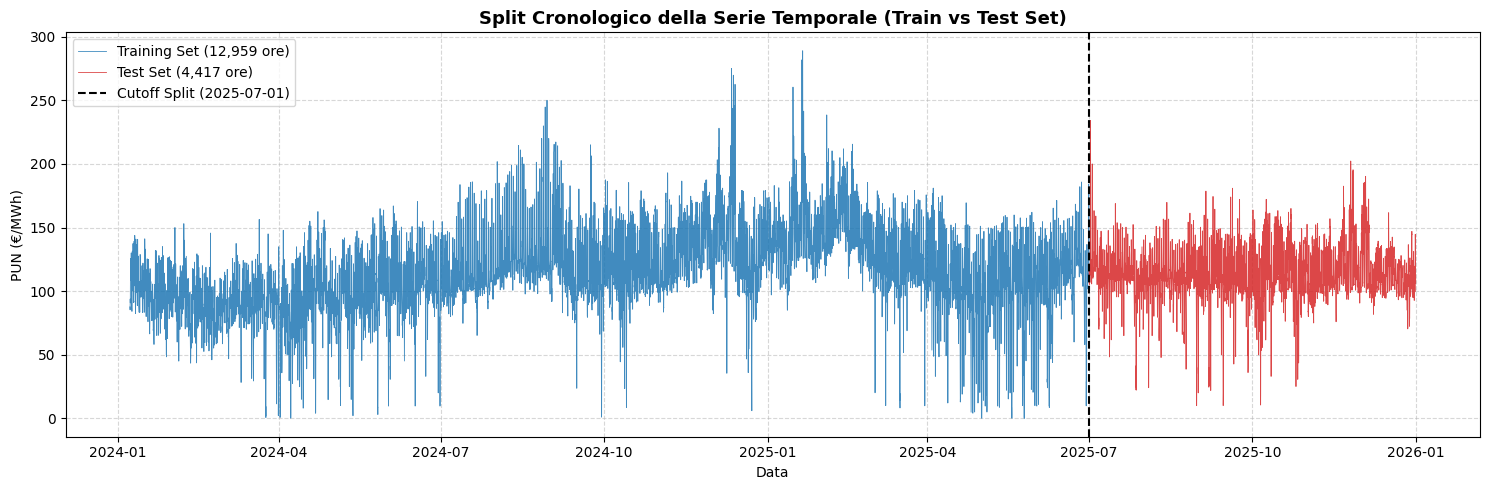

In [90]:
# --- VISUALIZZAZIONE 3: GRAFICO DELLO SPLIT CRONOLOGICO TRAIN / TEST ---

plt.figure(figsize=(15, 5))

# Plot del periodo di Training (Blu)
plt.plot(
    df_fe.loc[train_mask, 'timestamp'], 
    y_train, 
    color='#1f77b4', 
    label=f'Training Set ({len(y_train):,} ore)', 
    linewidth=0.6, 
    alpha=0.85
)

# Plot del periodo di Testing (Rosso)
plt.plot(
    df_fe.loc[test_mask, 'timestamp'], 
    y_test, 
    color='#d62728', 
    label=f'Test Set ({len(y_test):,} ore)', 
    linewidth=0.6, 
    alpha=0.85
)

# Linea verticale di cutoff (Soglia di split temporale)
plt.axvline(
    x=pd.to_datetime(data_cutoff), 
    color='black', 
    linestyle='--', 
    linewidth=1.5, 
    label=f'Cutoff Split ({data_cutoff.split()[0]})'
)

# Configurazione grafica e titoli
plt.title("Split Cronologico della Serie Temporale (Train vs Test Set)", fontsize=13, fontweight='bold')
plt.xlabel("Data")
plt.ylabel("PUN (€/MWh)")
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Esportazione dei Dataset Processati

In questa fase conclusiva salviamo le matrici di Training (`X_train`, `y_train`) e di Test (`X_test`, `y_test`) all'interno della cartella `data/processed/`.

Questi file CSV costituiscono il dataset pulito e pronto per essere importato nel secondo notebook (`02_modeling_multi_horizon.ipynb`), garantendo la completa separazione tra la fase di Data Preparation e quella di Modeling secondo le best practice del flusso CRISP-DM.

In [91]:
os.makedirs("data/processed", exist_ok=True)

X_train.to_csv("data/processed/X_train.csv", index=False)
y_train.to_csv("data/processed/y_train.csv", index=False)
X_test.to_csv("data/processed/X_test.csv", index=False)
y_test.to_csv("data/processed/y_test.csv", index=False)

print("Dataset per il Modeling salvati con successo in data/processed/")

Dataset per il Modeling salvati con successo in data/processed/


In [92]:
# --- CHECK DI INTEGRITÀ E CONTINUITÀ TEMPORALE ---
import pandas as pd

# 1. Verifica che non ci siano valori mancanti residui
print("🔍 Checking NaN totali:", df_fe.isnull().sum().sum())

# 2. Verifica continuità della serie temporale (se hai la colonna timestamp/Date)
if 'Date' in df_fe.columns or isinstance(df_fe.index, pd.DatetimeIndex):
    time_col = df_fe['Date'] if 'Date' in df_fe.columns else df_fe.index
    time_diffs = pd.to_datetime(time_col).diff().dropna()
    
    # Controlla se esistono salti temporali diversi da 1 ora
    salti_anomali = time_diffs[time_diffs != pd.Timedelta(hours=1)]
    print(f"⚠️ Salti temporali anomali riscontrati nella serie: {len(salti_anomali)}")
    if len(salti_anomali) > 0:
        print("Dettaglio primi salti anomali:\n", salti_anomali.head())
    else:
        print("✅ Serie temporale oraria perfettamente continua (passo di 1h esatto)!")

🔍 Checking NaN totali: 0
